# Display choices are analytical choices

**Objective:** Build a 3D display of measured values while making its height, support and perceptual limits explicit.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

A 3D column can encode temperature, reflectance or population. It should never imply terrain unless actual elevation was acquired. The explorer scene places measured red/green/blue reflectance on a geographic plane, then adds whole-tract population columns. It does not contain an elevation model.

In this figure, height is actual land surface temperature in Celsius. Perspective can hide columns and distort comparisons, so a 2D plot and the accessible table remain essential alternatives. Sample rows are thinned only for legibility; no values are generated.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=09_visualization_3d.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
sample = [r for r in data[::15] if r["temperature_c"] is not None]
print("Displayed actual sample count:", len(sample))
print("Height variable: land surface temperature in °C; not elevation.")

Displayed actual sample count: 460
Height variable: land surface temperature in °C; not elevation.


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

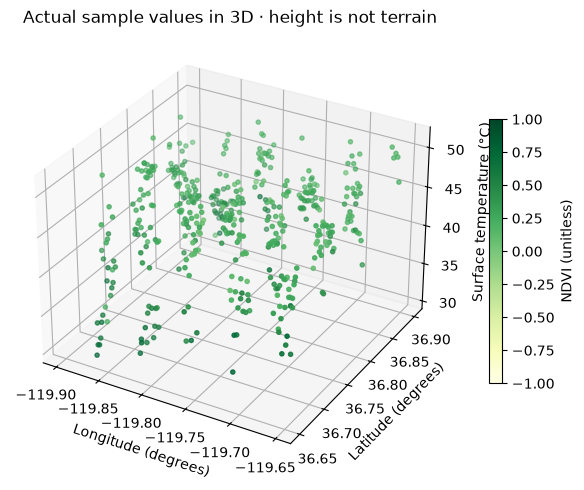

In [3]:
fig = plt.figure(figsize=(8,5))
ax = fig.add_subplot(111, projection="3d")
points = ax.scatter([r["lon"] for r in sample], [r["lat"] for r in sample],
                    [r["temperature_c"] for r in sample], c=[r["ndvi"] for r in sample],
                    cmap="YlGn", s=9, vmin=-1, vmax=1)
ax.set(xlabel="Longitude (degrees)", ylabel="Latitude (degrees)", zlabel="Surface temperature (°C)")
ax.set_title("Actual sample values in 3D · height is not terrain")
fig.colorbar(points, ax=ax, shrink=.6, label="NDVI (unitless)")
plt.tight_layout(); plt.show()

## Interpret and extend

Rotate the interactive explorer scene. Name two comparisons made harder by perspective. Recreate one comparison as a 2D chart with a numeric legend and explain which display you would publish.

## Sources and attribution

- [NASA, Landsat 9](https://science.nasa.gov/mission/landsat-9/).
- [USGS, Landsat Collection 2 surface temperature](https://www.usgs.gov/landsat-missions/landsat-collection-2-surface-temperature).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.